In [36]:
import io
import sys
from collections import Counter
from contextlib import redirect_stdout
from pathlib import Path
from tempfile import mkdtemp

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from imblearn.over_sampling import ADASYN, SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.dummy import DummyClassifier
from sklearn.feature_selection import (
    SelectFromModel,
    SequentialFeatureSelector,
    VarianceThreshold,
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    accuracy_score,
    average_precision_score,
    classification_report,
    cohen_kappa_score,
    confusion_matrix,
    log_loss,
    make_scorer,
    precision_recall_curve,
    precision_score,
    recall_score,
)
from sklearn.model_selection import (
    StratifiedGroupKFold,
    cross_val_predict,
    cross_val_score,
    cross_validate,
)
from sklearn.naive_bayes import BernoulliNB, GaussianNB, MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline  # Pipeline estándar
from sklearn.preprocessing import (
    MinMaxScaler,
    OneHotEncoder,
    StandardScaler,
)

# Enrutamiento de metadatos: lleva `groups` hasta el CV interno
# del selector de variables
sklearn.set_config(enable_metadata_routing=True)

sys.path.insert(0, str(Path.cwd().parent))

from config import config
from utils.evaluador_cv import EvaluadorCV


def cox_snell_r2(model, X, y):
    """
    Calcula el R² de Cox & Snell para Regresión Logística.
    Requires probabilidades predichas del modelo.
    """
    n = len(y)
    # Log-likelihood del modelo actual
    probs = model.predict_proba(X)
    ll_model = -log_loss(y, probs, normalize=False)

    # Log-likelihood del modelo nulo (solo intercepto)
    p_null = np.mean(y)
    ll_null = np.sum(y * np.log(p_null) + (1 - y) * np.log(1 - p_null))

    return 1 - np.exp((2 / n) * (ll_null - ll_model))


def nagelkerke_r2(model, X, y):
    """
    Calcula el R² de Nagelkerke ajustando la escala entre 0 y 1.
    """
    n = len(y)
    p_null = np.mean(y)
    ll_null = np.sum(y * np.log(p_null) + (1 - y) * np.log(1 - p_null))

    cs_r2 = cox_snell_r2(model, X, y)
    max_r2 = 1 - np.exp((2 / n) * ll_null)

    return cs_r2 / max_r2


DIR_SPLITS = config.DATADIR / "splits"
DIR_CACHE_PIPE = config.DATADIR / "cache_pipe"
DIR_CACHE_PIPE.mkdir(parents=True, exist_ok=True)

# test.pkl no se abre hasta la evaluación final del proyecto
df_train = pd.read_pickle(DIR_SPLITS / "train.pkl")
df_val = pd.read_pickle(DIR_SPLITS / "val.pkl")
assert list(df_train.columns) == list(df_val.columns)

# Papel de cada columna (ver la conclusión de eda_consolidate.ipynb)
LLAVES = ["DIRECTORIO", "SECUENCIA_P"]  # trazabilidad, nunca entran a X
GRUPO = "SEGMENTO"  # grupos para StratifiedGroupKFold
PESO = "PESO"  # solo si se pondera el modelo
OBJETIVO = "POBRE"
CARACTERISTICAS = [
    c for c in df_train.columns if c not in [*LLAVES, GRUPO, PESO, OBJETIVO]
]

RANDOM_STATE = 42

# Validar modelos

**Asistido por Claude Opus 5.5** como apoyo en la comprensión de conceptos metodológicos, la organización de ideas, la revisión de la redacción académica y la asistencia en tareas de programación (graficos). Estas herramientas se utilizaron como recursos complementarios y no sustituyen el análisis crítico ni las decisiones metodológicas de los autores. Los autores son responsables de verificar la información, validar los procedimientos y resultados presentados, y garantizar la integridad académica del trabajo.

# Cargar datos

In [37]:
X_train, y_train = df_train[CARACTERISTICAS], df_train[OBJETIVO]
grupos_train = df_train[GRUPO]
X_val, y_val = df_val[CARACTERISTICAS], df_val[OBJETIVO]
grupos_val = df_val[GRUPO]

pd.DataFrame(
    {
        "hogares": [len(df_train), len(df_val)],
        "tasa POBRE": [y_train.mean(), y_val.mean()],
    },
    index=["train", "val"],
)

,hogares,tasa POBRE
train,31039,0.128419
val,6643,0.128707


# Recuperar Pipelines

In [38]:
UMBRAL = 0.45

## Décima propuesta

In [39]:
C_log = np.logspace(-3, 2, 6)
param_grid_10 = [
    # Bloque 1: modelo final con regularización L2 (Ridge) o L1 (Lasso)
    # vía liblinear
    {
        # 1. Qué tan estricto es el selector Lasso (valores más bajos =
        # menos variables): [0.003, 0.009, 0.031, 0.1, 0.316, 1.0]
        "select_vars__estimator__C": np.logspace(-2.5, 0, 6),
        # Umbral de corte de coeficientes (1e-5 elimina los ceros exactos
        # de L1)
        "select_vars__threshold": [1e-5, "median", "mean"],
        # Tope opcional de variables (evita que entren demasiadas si C es
        # alto). Debe ser como mucho el número de columnas tras imputar
        # (8 o 9)
        "select_vars__max_features": [None, 4, 6],
        # 2. Modelo final. liblinear acepta l1_ratio=0 y l1_ratio=1
        "model__l1_ratio": [0.0, 1.0],  # 0.0 = Ridge (L2), 1.0 = Lasso (L1)
        "model__solver": ["liblinear"],
        "model__C": C_log,
    },
    # Bloque 2: modelo final con ElasticNet (mezcla L1 + L2) vía saga
    {
        "select_vars__estimator__C": np.logspace(-2.5, 0, 6),
        "select_vars__threshold": [1e-5, "median"],
        "select_vars__max_features": [None, 4, 6],
        "model__l1_ratio": [0.25, 0.5, 0.75],
        "model__solver": ["saga"],
        "model__C": C_log,
    },
]

lasso_selector_10 = LogisticRegression(
    l1_ratio=1,
    solver="liblinear",
    C=0.01,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    max_iter=1000,
)
model_log_reg_10 = LogisticRegression(
    class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE
)

# Pipeline Principal: igual a la sexta, con MinMax en lugar de StandardScaler
lasso_log_reg_10 = Pipeline(
    [
        (
            "imputer",
            SimpleImputer(
                strategy="constant", fill_value=0, add_indicator=True
            ),
        ),
        ("scaler", MinMaxScaler()),
        ("select_vars", SelectFromModel(lasso_selector_10)),
        ("model", model_log_reg_10),
    ],
    memory=str(DIR_CACHE_PIPE),
)

ev_10 = EvaluadorCV(
    lasso_log_reg_10,
    X_train,
    y_train,
    UMBRAL,
    grupos_train,
    pickle=True,
    grid=param_grid_10,
)
ev_10.evaluar_cv()
ev_10.resumen_metricas()

umbral: 0.45
Resultado cargado desde el caché: /Users/juanpablocarrillo/Desktop/Externado/Cuarto_semestre/Machine_learning_1/Multidimesional_poverty_in_Colombia/data/cache_cv/cv_dc4cd50be17dde0979a6ccdd3368249d.pkl
fit_time: 87.826 ± 6.266
score_time: 0.012 ± 0.001
test_accuracy: 0.629 ± 0.004
test_precision: 0.181 ± 0.003
test_recall: 0.535 ± 0.016
test_kappa: 0.097 ± 0.007
test_average_precision: 0.259 ± 0.012


## Onceava propuesta

In [40]:
# Grilla reducida: solo valores que cambian el resultado (0.001 y 0.005 de
# var_filter quitan la misma columna) o que la décima propuesta eligió
C_sel_11 = [0.00316, 0.0316, 0.316]  # uno sí, uno no del logspace
C_mod_11 = [0.01, 0.1, 1, 10]
param_grid_11 = [
    # Bloque 1: modelo final con regularización L2 (Ridge) o L1 (Lasso)
    # vía liblinear
    {
        "var_filter__threshold": [0.001, 0.01, 0.02],
        "select_vars__estimator__C": C_sel_11,
        "select_vars__threshold": [1e-5, "median", 0.10],
        "select_vars__max_features": [None, 4, 6],
        "model__l1_ratio": [0.0, 1.0],  # 0.0 = Ridge (L2), 1.0 = Lasso (L1)
        "model__solver": ["liblinear"],
        "model__C": C_mod_11,
    },
    # Bloque 2: ElasticNet vía saga (el más lento): una sola mezcla
    {
        "var_filter__threshold": [0.001, 0.01, 0.02],
        "select_vars__estimator__C": C_sel_11,
        "select_vars__threshold": [1e-5, "median", 0.10],
        "select_vars__max_features": [None, 4, 6],
        "model__l1_ratio": [0.5],
        "model__solver": ["saga"],
        "model__C": C_mod_11,
    },
]

lasso_selector_11 = LogisticRegression(
    l1_ratio=1,
    solver="liblinear",
    C=0.0316,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    max_iter=1000,
)

# 2. Clasificador final
model_log_reg_11 = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=RANDOM_STATE,
)

# 3. Pipeline automatizado: imputa con indicadores y filtra columnas casi
# constantes antes de escalar y seleccionar
lasso_log_reg_11 = Pipeline(
    [
        (
            "imputer",
            SimpleImputer(
                strategy="constant", fill_value=0, add_indicator=True
            ),
        ),
        # Descarta indicadores rarísimos
        ("var_filter", VarianceThreshold(threshold=0.001)),
        ("scaler", MinMaxScaler()),
        ("select_vars", SelectFromModel(lasso_selector_11, threshold=1e-05)),
        ("model", model_log_reg_11),
    ],
    memory=str(DIR_CACHE_PIPE),
)

ev_11 = EvaluadorCV(
    lasso_log_reg_11,
    X_train,
    y_train,
    UMBRAL,
    grupos_train,
    pickle=True,
    grid=param_grid_11,
)
ev_11.evaluar_cv()
ev_11.resumen_metricas()

umbral: 0.45
Resultado cargado desde el caché: /Users/juanpablocarrillo/Desktop/Externado/Cuarto_semestre/Machine_learning_1/Multidimesional_poverty_in_Colombia/data/cache_cv/cv_296f57e98049d43f3e92b5f7ad9d8b76.pkl
fit_time: 38.943 ± 1.993
score_time: 0.008 ± 0.001
test_accuracy: 0.629 ± 0.004
test_precision: 0.181 ± 0.003
test_recall: 0.535 ± 0.016
test_kappa: 0.097 ± 0.007
test_average_precision: 0.259 ± 0.012


# Entrenar usando todo Train

In [41]:
prop_10_full = ev_10.ajustar_final()
prop_11_full = ev_11.ajustar_final()

In [42]:
pipe_10 = prop_10_full.best_estimator_
pipe_11 = prop_11_full.best_estimator_

candidatas = {
    "prop 10": (pipe_10, prop_10_full),
    "prop 11": (pipe_11, prop_11_full),
}

# Evaluar en Validation set

En esta etapa se selecciona entre las 2 propuestas para pasar a la fase con el conjunto de test.

In [43]:
def look_details(pipe):
    # Ajusta el nombre del objeto GridSearchCV ganador
    grid_ganador = pipe  # o el nombre de tu objeto GridSearchCV
    pipe_ganador = grid_ganador.best_estimator_

    # Extraer nombres post-imputación y filtros aplicados dentro del Pipeline
    nombres_vars = pipe_ganador.named_steps["imputer"].get_feature_names_out()

    if "var_filter" in pipe_ganador.named_steps:
        nombres_vars = nombres_vars[
            pipe_ganador.named_steps["var_filter"].get_support()
        ]

    if "select_vars" in pipe_ganador.named_steps:
        nombres_vars = nombres_vars[
            pipe_ganador.named_steps["select_vars"].get_support()
        ]

    # Extraer coeficientes y Adjusted Odds Ratios (AOR)
    coefs = pipe_ganador.named_steps["model"].coef_.ravel()
    aors = np.exp(coefs)

    df_hiperparametros = pd.DataFrame([grid_ganador.best_params_])

    df_coefs_aor = (
        pd.DataFrame(
            {
                "Variable": nombres_vars,
                "Coeficiente (Beta)": coefs,
                "AOR (MinMax)": aors,
                "Magnitud_Abs_Beta": np.abs(coefs),
            }
        )
        .sort_values("Magnitud_Abs_Beta", ascending=False)
        .drop(columns="Magnitud_Abs_Beta")
        .reset_index(drop=True)
    )

    display(df_hiperparametros)
    display(df_coefs_aor.round(4))

In [44]:
look_details(prop_10_full)

,model__C,model__l1_ratio,model__solver,select_vars__estimator__C,select_vars__max_features,select_vars__threshold
0,0.1,0.0,liblinear,0.003162,None,median


,Variable,Coeficiente (Beta),AOR (MinMax)
0,ORG_analfabetismo,2.5434,12.7231
1,ORG_trabajo_infantil,0.8850,2.4229
2,ORG_servicio_sanitario,0.5476,1.7292
3,ORG_alcantarillado,0.3778,1.4590
4,missingindicator_ORG_trabajo_infantil,-0.2606,0.7706
5,ORG_acueducto,0.2439,1.2762
6,missingindicator_ORG_analfabetismo,0.1225,1.1304
7,ORG_sin_aseguramiento,-0.0477,0.9534
8,ORG_fuente_agua_cocinar,0.0186,1.0188


In [45]:
look_details(prop_11_full)

,model__C,model__l1_ratio,model__solver,select_vars__estimator__C,select_vars__max_features,select_vars__threshold,var_filter__threshold
0,0.1,0.0,liblinear,0.00316,None,median,0.001


,Variable,Coeficiente (Beta),AOR (MinMax)
0,ORG_analfabetismo,2.5434,12.7230
1,ORG_trabajo_infantil,0.8849,2.4227
2,ORG_servicio_sanitario,0.5475,1.7288
3,ORG_alcantarillado,0.3778,1.4591
4,missingindicator_ORG_trabajo_infantil,-0.2606,0.7706
5,ORG_acueducto,0.2440,1.2764
6,ORG_sin_aseguramiento,-0.0477,0.9534
7,ORG_fuente_agua_cocinar,0.0187,1.0189


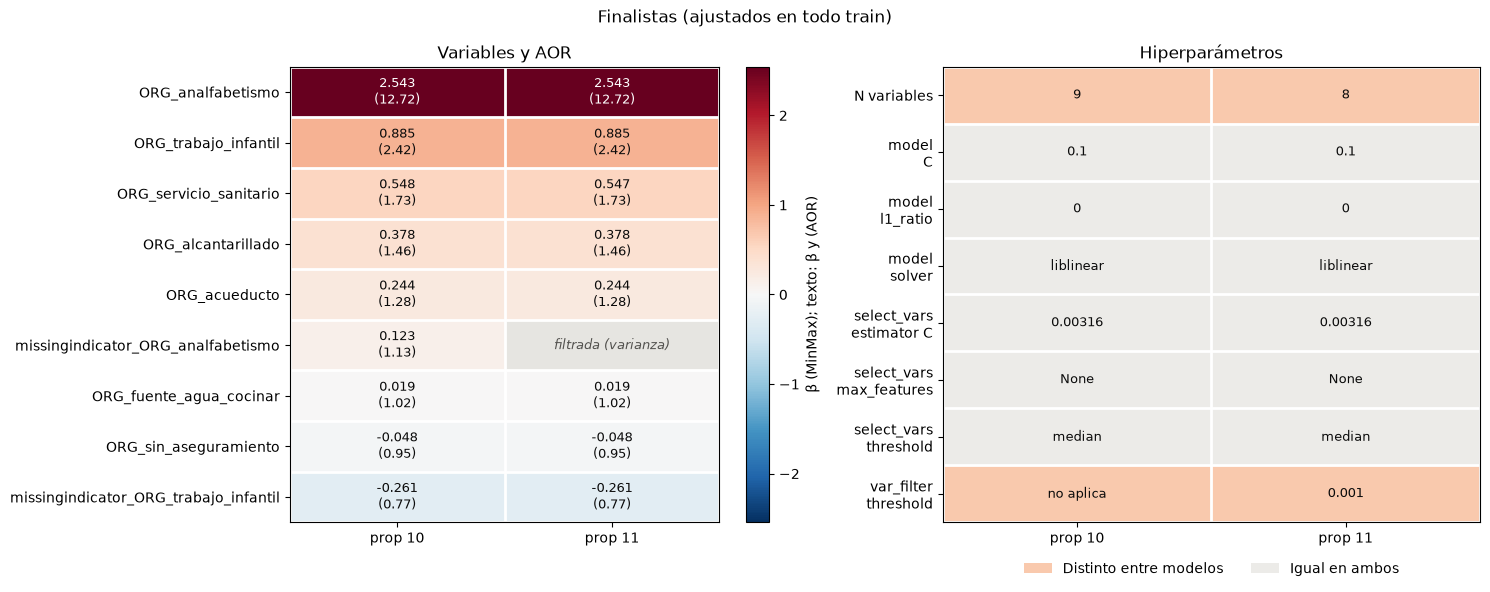

In [46]:
# Compare AOR, variables and hyperparameters
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

EVALUADORES = {"prop 10": ev_10, "prop 11": ev_11}
modelos = list(candidatas)

# Coeficiente de cada variable elegida y, para las que faltan, el motivo
betas, motivos = {}, {}
for nombre, (pipe_m, grid_m) in candidatas.items():
    columnas = EVALUADORES[nombre].X_train.columns
    seleccionadas = EVALUADORES[nombre].variables_seleccionadas(grid_m)
    betas[nombre] = pd.Series(
        pipe_m.named_steps["model"].coef_.ravel(), index=seleccionadas
    )
    # Salida del imputer y entrada del selector (después del filtro de
    # varianza, si lo hay)
    imputadas = pipe_m.named_steps["imputer"].get_feature_names_out(columnas)
    pasos = list(pipe_m.named_steps)
    entrada_selector = pipe_m[
        : pasos.index("select_vars")
    ].get_feature_names_out(columnas)
    motivos[nombre] = {
        var: (
            "no seleccionada"
            if var in entrada_selector
            else "filtrada (varianza)"
        )
        for var in imputadas
        if var not in seleccionadas
    }

# Variables x modelos, ordenadas por el β de la décima propuesta
beta_hm = pd.DataFrame(betas)[modelos]
beta_hm = beta_hm.loc[
    beta_hm[modelos[0]].sort_values(ascending=False, na_position="last").index
]


def texto_param(valor):
    """Texto corto de un hiperparámetro; NaN: el modelo no lo tiene."""
    if valor is None:
        return "None"
    if isinstance(valor, (float, np.floating)):
        return "no aplica" if np.isnan(valor) else f"{valor:.3g}"
    return str(valor)


def etiqueta_param(nombre):
    """'select_vars__estimator__C' -> 'select_vars\nestimator C'."""
    paso, _, resto = nombre.partition("__")
    if not resto:
        return nombre
    return f"{paso}\n{resto.replace('estimator__', 'estimator ')}"


# Hiperparámetros: el color solo marca si difieren entre los modelos
params_hm = pd.DataFrame(
    {
        nombre: pd.Series(grid_m.best_params_, dtype=object)
        for nombre, (_, grid_m) in candidatas.items()
    }
)[modelos].sort_index()
params_hm.loc["N variables"] = [len(betas[nombre]) for nombre in modelos]
params_hm = params_hm.loc[["N variables", *params_hm.index[:-1]]]
texto_hm = params_hm.map(texto_param)
difiere_hm = (texto_hm.nunique(axis=1) > 1).to_numpy(dtype=int)

COLOR_IGUAL, COLOR_DISTINTO = "#ecebe8", "#f9c9ad"
COLOR_SIN_COEF = "#e6e5e1"

fig, (ax_b, ax_h) = plt.subplots(1, 2, figsize=(15, 6))

# 1. Coeficientes: divergente centrado en 0 (rojo sube las odds de
# pobreza, azul las baja)
vmax = np.nanmax(np.abs(beta_hm.to_numpy(dtype=float)))
ax_b.set_facecolor(COLOR_SIN_COEF)  # celdas sin coeficiente (NaN)
im = ax_b.imshow(
    beta_hm.to_numpy(dtype=float),
    cmap="RdBu_r",
    vmin=-vmax,
    vmax=vmax,
    aspect="auto",
)
for i, variable in enumerate(beta_hm.index):
    for j, nombre in enumerate(modelos):
        beta = beta_hm.iat[i, j]
        if np.isnan(beta):
            ax_b.text(
                j,
                i,
                motivos[nombre].get(variable, "no seleccionada"),
                ha="center",
                va="center",
                color="#52514e",
                fontsize=9,
                style="italic",
            )
        else:
            ax_b.text(
                j,
                i,
                f"{beta:.3f}\n({np.exp(beta):.2f})",
                ha="center",
                va="center",
                color="white" if abs(beta) > 0.6 * vmax else "#0b0b0b",
                fontsize=9,
            )
ax_b.set_yticks(np.arange(len(beta_hm)), labels=beta_hm.index)
fig.colorbar(im, ax=ax_b, label="β (MinMax); texto: β y (AOR)")
ax_b.set_title("Variables y AOR")

# 2. Hiperparámetros: naranja si difieren entre los dos modelos
ax_h.imshow(
    np.repeat(difiere_hm[:, None], len(modelos), axis=1),
    cmap=ListedColormap([COLOR_IGUAL, COLOR_DISTINTO]),
    vmin=0,
    vmax=1,
    aspect="auto",
)
for i in range(len(texto_hm)):
    for j in range(len(modelos)):
        ax_h.text(
            j,
            i,
            texto_hm.iat[i, j],
            ha="center",
            va="center",
            color="#0b0b0b",
            fontsize=9,
        )
ax_h.set_yticks(
    np.arange(len(texto_hm)),
    labels=[etiqueta_param(p) for p in texto_hm.index],
)
ax_h.legend(
    handles=[
        Patch(facecolor=COLOR_DISTINTO, label="Distinto entre modelos"),
        Patch(facecolor=COLOR_IGUAL, label="Igual en ambos"),
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, -0.06),
    ncol=2,
    frameon=False,
)
ax_h.set_title("Hiperparámetros")

# Columnas = modelos y líneas blancas entre celdas
for ax, n_filas in ((ax_b, len(beta_hm)), (ax_h, len(texto_hm))):
    ax.set_xticks(np.arange(len(modelos)), labels=modelos)
    ax.set_xticks(np.arange(-0.5, len(modelos)), minor=True)
    ax.set_yticks(np.arange(-0.5, n_filas), minor=True)
    ax.grid(which="minor", color="white", linewidth=2)
    ax.tick_params(which="minor", length=0)

fig.suptitle("Finalistas (ajustados en todo train)")
fig.tight_layout()
plt.show()

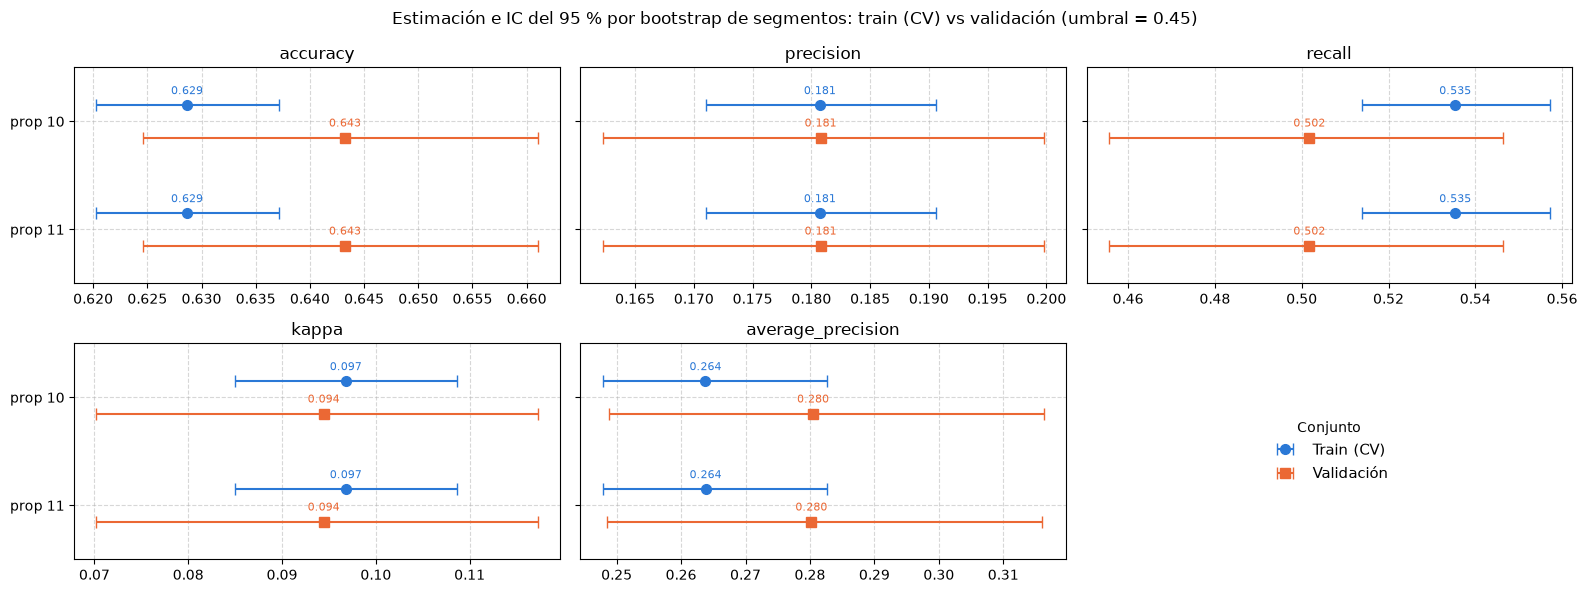

In [47]:
# Compare bootstrap metrics of prop 10 in val and train, and also prop 11
# train vs val
METRICAS_IC = [
    "accuracy",
    "precision",
    "recall",
    "kappa",
    "average_precision",
]


def bootstrap_val(
    y, proba, grupos, umbral, n_boot=1000, alpha=0.05, random_state=None
):
    """IC por bootstrap de segmentos sobre un conjunto reservado.

    Misma lógica que EvaluadorCV.bootstrap_ic: cada réplica remuestrea
    segmentos completos con reemplazo (como pesos de sus filas) y recalcula
    las métricas. Con la misma semilla y los mismos grupos, todos los
    modelos reciben las mismas réplicas (comparación pareada).
    """
    if random_state is None:
        random_state = RANDOM_STATE
    y = np.asarray(y).astype(int)
    proba = np.asarray(proba)
    pred = (proba >= umbral).astype(int)
    codigos, grupos_unicos = pd.factorize(np.asarray(grupos))
    n_grupos = len(grupos_unicos)
    # Celda de la matriz de confusión: 0=TN, 1=FP, 2=FN, 3=TP
    celda = 2 * y + pred

    def metricas(pesos):
        tn, fp, fn, tp = np.bincount(celda, weights=pesos, minlength=4)
        n = tn + fp + fn + tp
        p_o = (tp + tn) / n
        p_e = ((tp + fp) * (tp + fn) + (fn + tn) * (fp + tn)) / n**2
        usar = pesos > 0
        return {
            "accuracy": p_o,
            "precision": tp / (tp + fp) if tp + fp > 0 else 0.0,
            "recall": tp / (tp + fn) if tp + fn > 0 else 0.0,
            "kappa": (p_o - p_e) / (1 - p_e) if p_e < 1 else 0.0,
            "average_precision": average_precision_score(
                y[usar], proba[usar], sample_weight=pesos[usar]
            ),
        }

    rng = np.random.default_rng(random_state)
    replicas = pd.DataFrame(
        [
            metricas(
                np.bincount(
                    rng.integers(0, n_grupos, n_grupos), minlength=n_grupos
                )[codigos].astype(float)
            )
            for _ in range(n_boot)
        ]
    )
    return pd.DataFrame(
        {
            "estimacion": pd.Series(metricas(np.ones(len(y)))),
            "ic_inf": replicas.quantile(alpha / 2),
            "ic_sup": replicas.quantile(1 - alpha / 2),
        }
    ).rename_axis("metrica")


# Train: predicciones fuera de pliegue de la CV; validación: el modelo
# ajustado en todo train sobre df_val. Mismo umbral (UMBRAL) en ambos
resumen_conjuntos = pd.concat(
    {
        "Train (CV)": pd.concat(
            {nombre: EVALUADORES[nombre].bootstrap_ic() for nombre in modelos},
            names=["modelo"],
        ),
        "Validación": pd.concat(
            {
                nombre: bootstrap_val(
                    y_val,
                    pipe_m.predict_proba(X_val)[:, 1],
                    grupos_val,
                    UMBRAL,
                )
                for nombre, (pipe_m, _) in candidatas.items()
            },
            names=["modelo"],
        ),
    },
    names=["conjunto"],
)

COLORES_CONJUNTO = {"Train (CV)": "#2a78d6", "Validación": "#eb6834"}
MARCADORES_CONJUNTO = {"Train (CV)": "o", "Validación": "s"}
# Train arriba y validación abajo dentro de la fila de cada modelo
DESPLAZAMIENTO_CONJUNTO = {"Train (CV)": 0.15, "Validación": -0.15}
y_ic = np.arange(len(modelos))[::-1]  # el primer modelo queda arriba

fig, axes = plt.subplots(2, 3, figsize=(16, 6), sharey=True)
for ax, metrica in zip(axes.flat, METRICAS_IC):
    for conjunto, color in COLORES_CONJUNTO.items():
        datos = resumen_conjuntos.xs(
            (conjunto, metrica), level=["conjunto", "metrica"]
        ).reindex(modelos)
        # Un percentil del bootstrap puede quedar justo en la estimación
        error = np.clip(
            [
                datos["estimacion"] - datos["ic_inf"],
                datos["ic_sup"] - datos["estimacion"],
            ],
            0,
            None,
        )
        ax.errorbar(
            datos["estimacion"],
            y_ic + DESPLAZAMIENTO_CONJUNTO[conjunto],
            xerr=error,
            fmt=MARCADORES_CONJUNTO[conjunto],
            color=color,
            markersize=7,
            capsize=4,
            lw=1.5,
            label=conjunto,
        )
        # Valor estimado encima de cada punto
        for x, y in zip(
            datos["estimacion"], y_ic + DESPLAZAMIENTO_CONJUNTO[conjunto]
        ):
            ax.annotate(
                f"{x:.3f}",
                (x, y),
                xytext=(0, 6),
                textcoords="offset points",
                ha="center",
                va="bottom",
                fontsize=8,
                color=color,
            )
    ax.set_yticks(y_ic, labels=modelos)
    ax.set_ylim(-0.5, len(modelos) - 0.5)
    ax.set_title(metrica)
    ax.grid(True, linestyle="--", alpha=0.5)

# Sexto panel: la leyenda
axes.flat[-1].axis("off")
axes.flat[-1].legend(
    *axes.flat[0].get_legend_handles_labels(),
    loc="center",
    title="Conjunto",
    frameon=False,
    fontsize=11,
)
fig.suptitle(
    "Estimación e IC del 95 % por bootstrap de segmentos: train (CV) vs "
    f"validación (umbral = {UMBRAL})"
)
fig.tight_layout()
plt.show()

Note que ambas propuestas tienen un rendimiento prácticamente igual, pues mantienen la misma variabilidad en sus métricas. Además, presentan prácticamente los mismos coeficientes así como hiperparámetros prácticamente iguales, la única diferencia es que la onceava propuesta utiliza una variable menos, por lo que es más parsimonioso al eliminar esa variable que solo era 1 en una fila, luego se toma esta por ganadora ya que:

- Tiene un recall alto (como es de esperar a costa de una precisión baja).
- Mantiene un rendimiento igual a la otra propuesta pero con un conjunto de variables más parsimonioso.
- Es interpretable (mantiene interpretación de porcentajes de manera natural al usar MinMaxScaler).
- Tiene la ventaja de ser más rápido de entrenar que propuestas descartadas en la fase anterior al usar una selección de características embebida y no SFS (útil si es necesario reentrenar el modelo y considerar nuevas variables).

> Nota: a pesar de haber gastado tanto el conjunto de entrenamiento al probar con tantas propuestas de modelación, las estimaciones no fueron tan optimistas como se esperaba.


Por lo tanto, en principio (antes del ajuste final) el modelo tiene un rendimiento moderado en el problema planteado que es detectar hogares multidimensionalmente pobres, aunque con el problema de que como sugiere su baja precisión tiende a clasificar como pobres muchos hogares que no lo son, sin embargo, se prefiere esto a dejar a hogares vulnerables sin ayudas de las cuales depende su subsistencia.

### Resumen de razones de descarte de modelos y su razón.

| Modelo | Razón de descarte | Fase de descarte |
| :--- | :--- | :--- |
| 0 Dummy | Modelo base de referencia (*baseline*) | Validación cruzada (entrenamiento) |
| 1 LR pesos | Se descartó ya que no estandarizaba o escalaba las variables, lo cual es dañino para la regularización por defecto que da `sklearn` y dificulta la comparación entre coeficientes. | Validación cruzada (entrenamiento) |
| 2 LR pesos MinMax | Se descarta ya que la selección de variables con SFS hace innecesariamente costoso el entrenamiento/reentrenamiento. | Validación cruzada (entrenamiento) |
| 3 LR SMOTE | Se descarta por su alta variabilidad de rendimiento de *fold* a *fold*, lo cual se ve mitigado al usar *bootstrap* para estimar, pero aun así esta inestabilidad baja la confianza en sus resultados, ya que los demás son estables en ambos gráficos. Además, tiene un bajo *recall*, el cual, si bien tiene picos de rendimiento, son muy inestables. | Validación cruzada (entrenamiento) |
| 4 LR ADASYN | Se descarta por su alta variabilidad de rendimiento de *fold* a *fold*, lo cual se ve mitigado al usar *bootstrap* para estimar, pero aun así esta inestabilidad baja la confianza en sus resultados, ya que los demás son estables en ambos gráficos. Además, tiene un bajo *recall*, el cual, si bien tiene picos de rendimiento, son muy inestables. | Validación cruzada (entrenamiento) |
| 5 LR submuestreo | Se descarta por su alta variabilidad de rendimiento de *fold* a *fold*, lo cual se ve mitigado al usar *bootstrap* para estimar, pero aun así esta inestabilidad baja la confianza en sus resultados, ya que los demás son estables en ambos gráficos. Además, tiene un bajo *recall*, el cual, si bien tiene picos de rendimiento, son muy inestables. | Validación cruzada (entrenamiento) |
| 6 LR Lasso | Dificulta la interpretabilidad en variables que son proporciones (como las del set) al modificar el rango de $[0, 1]$. | Validación cruzada (entrenamiento) |
| 7 Bernoulli NB | Pierde la interpretabilidad simple que se tiene con regresión logística; aunque rinda marginalmente mejor en *recall*, se omite ya que interpretarlo es más complicado para *stakeholders*. | Validación cruzada (entrenamiento) |
| 8 KNN submuestreo | Tiene un *recall* extremadamente bajo (independientemente del umbral, siempre es bajo). | Validación cruzada (entrenamiento) |
| 9 LR pesos estándar | Dificulta la interpretabilidad en variables que son proporciones (como las del set) al modificar el rango de $[0, 1]$. | Validación cruzada (entrenamiento) |
| 10 LR Lasso MinMax | Menos parsimonioso que el ganador. | Conjunto de validación |
| 11 LR Lasso filtro varianza | **Modelo ganador (no descartado)** | — |

# Pipeline Final

Ahora se da paso a definir una pipeline simplificada, que elimina los pasos de selección de variables, hiperparámetros y filtros de variabilidad, y solo deja el escalado de las variables y la imputación (junto con el indicador de nulidad retenido). En esta pipeline se fijan las 8 variables seleccionadas y los hiperparámetros definidos previamente, reentrenando el modelo sobre el conjunto unificado de train + validation.

In [48]:
final_log_reg = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=RANDOM_STATE,
    C=0.1,
    l1_ratio=0,
    solver="liblinear",
)

fill_imputer = ColumnTransformer(
    transformers=[
        (
            "fill_0_ind",
            SimpleImputer(
                strategy="constant", fill_value=0, add_indicator=True
            ),
            ["ORG_trabajo_infantil"],
        ),
        (
            "fill_0_no_ind",
            SimpleImputer(
                strategy="constant",
                fill_value=0,
            ),
            ["ORG_analfabetismo"],
        ),
    ],
    remainder="passthrough",
)

final_pipeline = Pipeline(
    [
        ("imputer", fill_imputer),
        ("scaler", MinMaxScaler()),
        ("model", final_log_reg),
    ],
    memory=str(DIR_CACHE_PIPE),
)

In [49]:
# Entrenar la pipeline final

X_train_val = pd.concat([X_train, X_val], axis=0)
y_train_val = pd.concat([y_train, y_val], axis=0)

final_pipeline.fit(X_train_val, y_train_val)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('scaler', ...), ...]"
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",'/Users/juanpablocarril...olombia/data/cache_pipe'
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['ORG_analfabetismo','ORG_trabajo_infantil','ORG_sin_aseguramiento',..., 'ORG_fuente_agua_cocinar','ORG_alcantarillado','ORG_servicio_sanitario']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('fill_0_ind', ...), ('fill_0_no_ind', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and c

In [50]:
X_train_val["ORG_trabajo_infantil"].isna().sum()

np.int64(29917)

In [51]:
X_train_val["ORG_trabajo_infantil"].isna().sum() / X_train_val.shape[0]

np.float64(0.7939334430231941)

# Evaluación final

In [52]:
# cargar conjunto de prueba final
df_test = pd.read_pickle(DIR_SPLITS / "test.pkl")
X_test, y_test = df_test[CARACTERISTICAS], df_test[OBJETIVO]

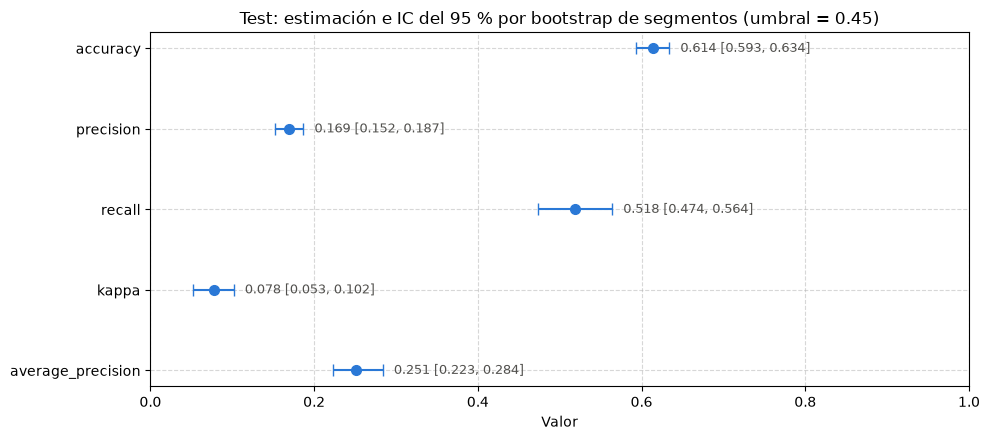

In [53]:
# IC del 95 % de las métricas en test (bootstrap de segmentos)
grupos_test = df_test[GRUPO]
proba_test = final_pipeline.predict_proba(X_test)[:, 1]
resumen_test = bootstrap_val(y_test, proba_test, grupos_test, UMBRAL)

datos_test = resumen_test.reindex(METRICAS_IC)
y_metricas = np.arange(len(METRICAS_IC))[::-1]  # accuracy queda arriba

fig, ax = plt.subplots(figsize=(10, 4.5))
# Un percentil del bootstrap puede quedar justo en la estimación
error = np.clip(
    [
        datos_test["estimacion"] - datos_test["ic_inf"],
        datos_test["ic_sup"] - datos_test["estimacion"],
    ],
    0,
    None,
)
ax.errorbar(
    datos_test["estimacion"],
    y_metricas,
    xerr=error,
    fmt="o",
    color="#2a78d6",
    markersize=7,
    capsize=4,
    lw=1.5,
)
# Estimación e intervalo escritos a la derecha de cada barra
for y, (est, inf, sup) in zip(
    y_metricas,
    datos_test[["estimacion", "ic_inf", "ic_sup"]].itertuples(index=False),
):
    ax.annotate(
        f"{est:.3f} [{inf:.3f}, {sup:.3f}]",
        (sup, y),
        xytext=(8, 0),
        textcoords="offset points",
        va="center",
        fontsize=9,
        color="#52514e",
    )
ax.set_yticks(y_metricas, labels=METRICAS_IC)
ax.set_xlim(min(0, datos_test["ic_inf"].min() - 0.05), 1)
ax.set_xlabel("Valor")
ax.set_title(
    "Test: estimación e IC del 95 % por bootstrap de segmentos "
    f"(umbral = {UMBRAL})"
)
ax.grid(True, linestyle="--", alpha=0.5)
fig.tight_layout()
plt.show()

En esta evaluación el modelo demostró tener un rendimiento similar a las etapas de validación (caen prácticamente en los rangos observados en etapas anteriores) y de entrenamiento, lo cual da una alta confianza sobre su rendimiento en producción, a esa confianza se le suma la estrechez general de sus intervalos, aunque el intervalo para la métrica crítica (recall) es considerablemente el más ancho, aun así en su límite inferior vale 0.474 lo cual aún se considera aceptable. Es importante hacer seguimiento del rendimiento del modelo respecto a esa métrica en productivo para mitigar las dudas que deja este intervalo ligeramente ancho.

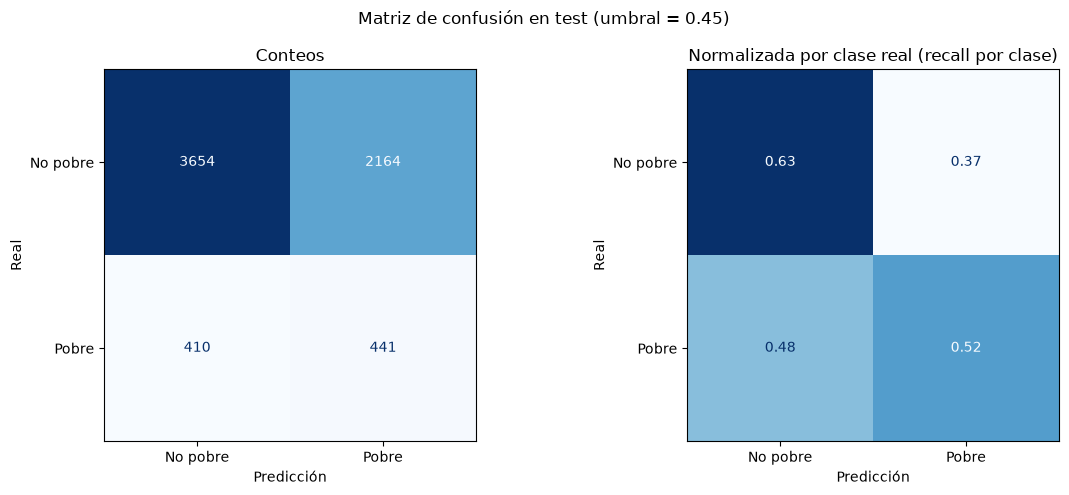

In [54]:
# Matriz de confusión en test con el umbral final
pred_test = (proba_test >= UMBRAL).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, normalizar, titulo, formato in zip(
    axes,
    (None, "true"),
    ("Conteos", "Normalizada por clase real (recall por clase)"),
    ("d", ".2f"),
):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        pred_test,
        normalize=normalizar,
        display_labels=["No pobre", "Pobre"],
        cmap="Blues",
        values_format=formato,
        colorbar=False,
        ax=ax,
    )
    ax.set_title(titulo)
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Real")
fig.suptitle(f"Matriz de confusión en test (umbral = {UMBRAL})")
fig.tight_layout()
plt.show()

Esta matriz permite observar de manera clara el comportamiento del modelo, efectivamente como sugiere su recall aproximadamente la mitad de pobres los clasifica bien y la otra mitad no los detecta, y se comporta relativamente bien a la hora de identificar no pobres como no pobres, esto sugiere que no son tantos los no pobres de la muestra que clasifica como pobres (FPR, en la esquina superior derecha moderado), sin embargo, eso no elimina el trade off que se hizo con la precisión, que genera que las alertas de pobreza del modelo generalmente no sean muy confiables y tiendan a saltar también con hogares no pobres.

No obstante, esto es una limitación la cual no se pudo mejorar y se acepta al mejorar el recall ya que darle ayudas estatales a un hogar que no lo necesita solo implica cierta fuga económica, sin embargo, no dar ayudas a hogares que lo necesitan (recall bajo) implica dejar hogares sin sustento.

> Nota: recuerde que por el desbalance el FPR se ve más alto de lo que realmente refleja el rendimiento del modelo, por lo que no lo use como guía, es solo una comparación del comportamiento del modelo según clase, para sacar conclusiones del rendimiento del modelo para dar predicciones confiables sin dar falsas alarmas guíese por la precisión. 

> Nota (ajustada por Gemini): Nota: Recuerde que, debido al desbalance de clases, el 
FPR($0.37$) resulta moderado en términos relativos por clase, pero representa un volumen alto de falsas alarmas en conteos absolutos ($2164$). Por ello, no lo utilice como guía principal; tómelo únicamente como una comparación del comportamiento del modelo por clase real. Para extraer conclusiones sobre la confiabilidad del modelo al emitir predicciones positivas sin generar falsas alarmas, guíese por la precisión.

/Users/juanpablocarrillo/Desktop/Externado/Cuarto_semestre/Machine_learning_1/Multidimesional_poverty_in_Colombia/.venv/lib/python3.14/site-packages/sklearn/utils/_plotting.py:193: FutureWarning: `**kwargs` is deprecated and will be removed in 1.11. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(


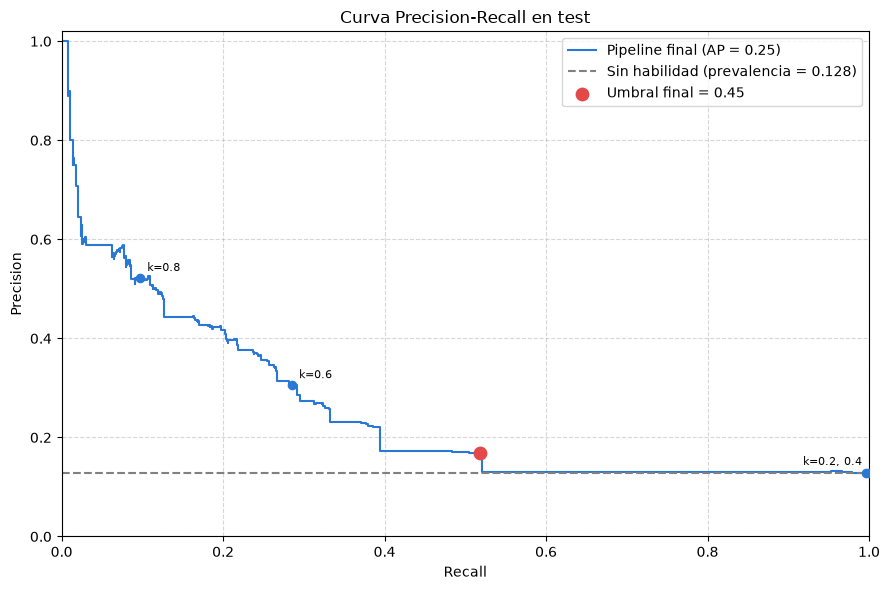

In [55]:
# Curva precisión-recall en test
fig, ax = plt.subplots(figsize=(9, 6))
PrecisionRecallDisplay.from_predictions(
    y_test, proba_test, name="Pipeline final", ax=ax, color="#2a78d6"
)
# Modelo sin habilidad: precisión igual a la prevalencia en todo recall
prevalencia = y_test.mean()
ax.axhline(
    prevalencia,
    color="grey",
    linestyle="--",
    label=f"Sin habilidad (prevalencia = {prevalencia:.3f})",
)

# Puntos de la curva para algunos umbrales k (cálculo exacto en cada k).
# Umbrales con puntos casi iguales (a menos de 0.05 en recall y en
# precisión) comparten una sola etiqueta para que no se encimen
grupos_k = []  # [(recall, precisión, [k, ...]), ...]
for k in (0.2, 0.4, 0.6, 0.8):
    pred_k = proba_test >= k
    r_k = recall_score(y_test, pred_k, zero_division=0)
    p_k = precision_score(y_test, pred_k, zero_division=0)
    ax.scatter(r_k, p_k, color="#2a78d6", s=35, zorder=5)
    cercano = next(
        (
            g
            for g in grupos_k
            if abs(g[0] - r_k) < 0.05 and abs(g[1] - p_k) < 0.05
        ),
        None,
    )
    if cercano is None:
        grupos_k.append((r_k, p_k, [k]))
    else:
        cercano[2].append(k)
for r_k, p_k, ks in grupos_k:
    ax.annotate(
        "k=" + ", ".join(f"{k:g}" for k in ks),
        (r_k, p_k),
        xytext=(-5, 6) if r_k > 0.9 else (5, 5),
        ha="right" if r_k > 0.9 else "left",
        textcoords="offset points",
        fontsize=8,
    )

# Punto de operación: el umbral final
ax.scatter(
    recall_score(y_test, pred_test),
    precision_score(y_test, pred_test, zero_division=0),
    color="#e34948",
    s=80,
    zorder=6,
    label=f"Umbral final = {UMBRAL}",
)
# from_predictions deja los ejes cuadrados; se usa todo el ancho
ax.set_aspect("auto")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Curva Precision-Recall en test")
ax.legend(loc="upper right")
ax.grid(True, linestyle="--", alpha=0.5)
fig.tight_layout()
plt.show()

La curva respalda la selección que se hizo en train para el umbral, ya que tal como ocurría en la etapa de entrenamiento el umbral que se tomó está justo en el límite en el que la curva cae a una precisión ridícula (el codo), es decir, se tiene el umbral que da el mejor recall sin tener una precisión escandalosamente baja.

In [56]:
# Interpretación con cambio de 0.1 en proporciones y de una categoría en
# ordinales (misma tabla que tabla_delta en modeling.ipynb, sin mínimo ni
# máximo entre pliegues porque hay un solo ajuste)
DELTA = 0.1
imputer_final = final_pipeline.named_steps["imputer"]
# Nombres sin el prefijo del ColumnTransformer ("remainder__ORG_...")
nombres_final = [
    nombre.split("__", 1)[1]
    for nombre in imputer_final.get_feature_names_out()
]
coefs_final = pd.Series(
    final_pipeline.named_steps["model"].coef_.ravel(), index=nombres_final
)
# Rango original de cada variable: lo que MinMax lleva a 1
rango_final = pd.Series(
    final_pipeline.named_steps["scaler"].data_range_, index=nombres_final
)

# Tipo de cada variable según sus valores en train + val, ya imputada
x_imputada_final = pd.DataFrame(
    imputer_final.transform(X_train_val),
    columns=nombres_final,
    index=X_train_val.index,
)


def tipo_variable(valores):
    if valores.nunique() == 2:
        return "binaria"
    if valores.between(0, 1).all() and (valores % 1 != 0).any():
        return "proporción"
    return "ordinal"


tipo_final = pd.Series(
    {var: tipo_variable(x_imputada_final[var]) for var in nombres_final}
)
# Binarias: cambio completo (AOR original); proporciones: 10 puntos
# porcentuales (0.1); ordinales: una categoría, que en la escala MinMax es
# 1 / rango (así el OR se lee por categoría y no por fracciones de ella)
delta_final = pd.Series(
    np.select(
        [tipo_final == "binaria", tipo_final == "ordinal"],
        [1.0, 1 / rango_final],
        default=DELTA,
    ),
    index=nombres_final,
)
# Qué cambio compara el OR de cada fila
CAMBIO_POR_TIPO = {
    "binaria": "cambio completo",
    "proporción": "+10 puntos porcentuales",
    "ordinal": "+1 categoría (peor)",
}

# OR para el cambio: AOR^delta
aor_final = np.exp(coefs_final)
tabla_delta_final = pd.DataFrame(
    {
        "Tipo": tipo_final,
        "AOR": aor_final,
        "Delta_escalado": delta_final,
        "Cambio interpretado": tipo_final.map(CAMBIO_POR_TIPO),
        "OR_delta": aor_final**delta_final,
    }
)
# Cambio porcentual de los odds de pobreza
tabla_delta_final["Cambio_odds_%"] = (tabla_delta_final["OR_delta"] - 1) * 100
tabla_delta_final["Delta_original"] = delta_final * rango_final


def valores_variable(valores, tipo):
    """Comportamiento observado: rango de las proporciones y ordinales,
    los dos valores de las binarias."""
    if tipo == "binaria":
        a, b = sorted(valores.unique())
        return f"{{{a:g}, {b:g}}}"
    return f"[{valores.min():g}, {valores.max():g}]"


# Valores que toma cada variable en train + val, tal como entra al modelo
# (ya imputada)
tabla_delta_final.insert(
    1,
    "Valores Observados en entrenamiento",
    [
        valores_variable(x_imputada_final[var], tipo_final[var])
        for var in nombres_final
    ],
)
tabla_delta_final.sort_values("OR_delta", ascending=False).round(3)

,Tipo,Valores Observados en entrenamiento,AOR,Delta_escalado,Cambio interpretado,OR_delta,Cambio_odds_%,Delta_original
ORG_alcantarillado,binaria,"{1, 2}",1.471,1.000,cambio completo,1.471,47.088,1.0
ORG_analfabetismo,proporción,"[0, 1]",13.491,0.100,+10 puntos porcentuales,1.297,29.719,0.1
ORG_acueducto,binaria,"{1, 2}",1.186,1.000,cambio completo,1.186,18.593,1.0
ORG_servicio_sanitario,ordinal,"[1, 6]",1.856,0.200,+1 categoría (peor),1.132,13.169,1.0
ORG_trabajo_infantil,proporción,"[0, 1]",2.608,0.100,+10 puntos porcentuales,1.101,10.060,0.1
ORG_fuente_agua_cocinar,ordinal,"[1, 10]",0.994,0.111,+1 categoría (peor),0.999,-0.071,1.0
ORG_sin_aseguramiento,proporción,"[0, 1]",0.909,0.100,+10 puntos porcentuales,0.991,-0.949,0.1
missingindicator_ORG_trabajo_infantil,binaria,"{0, 1}",0.773,1.000,cambio completo,0.773,-22.684,1.0


A continuación se da paso a la interpretación de los coeficientes, para las siguientes interpretaciones se considera que las demás variables están fijas:

- **ORG_alcantarillado:** es la variable binaria que muestra el cambio más drástico en los odds, suponiendo así que los odds de que un hogar sin alcantarillado sea multidimensional pobre son 1.471 veces más grandes que los que tendría un hogar que sí que tiene acceso o en otras palabras sus odds son $47.09\%$ más grandes respecto al hogar con acceso a este servicio, por lo tanto, es el Factor de conversión (enfoque de Sen).

- **ORG_analfabetismo:** Esta proporción supone el mayor cambio respecto a un hogar en el que no hay analfabetas contra uno en el que todos son analfabetas, pues un hogar donde todos son analfabetas tienen unos odds $1249.1\%$ más grandes que un hogar en el que no hay analfabetas, sin embargo, este cambio es abrupto, por lo que se prefiere interpretar como un cambio de 10 puntos porcentuales, el cual indica que por cada 10 puntos porcentuales que se aumenta la cantidad de analfabetas en el hogar los odds aumentan en un $29.719\%$, otra lectura interesante es la diferencia tan abismal que existe entre un hogar donde todos leen contra en el que nadie lee y escriben posicionando así la educación como una capacidad (según el enfoque de Sen) clave en la pobreza multidimensional.

- **ORG_acueducto:** Este es otro factor de conversión que indica que los hogares sin acceso al acueducto tienen unos odds $1.186$ veces los de un hogar que tiene acceso a este.

- **ORG_servicio_sanitario:** Es una variable ordinal que va de 1 (inodoro conectado a alcantarillado) a 6 (no tiene servicio sanitario), MinMax la lleva a $[0, 1]$ dividiendo por su rango ($6 - 1 = 5$), así que una unidad escalada equivale a recorrer toda la escala, luego pasar de la mejor a la peor categoría multiplica los odds de pobreza por $1.856$ (los aumenta en un $85.5\%$); es más fácil interpretarlo como el paso a la categoría siguiente, que es un cambio escalado de $1/5 = 0.2$ (que representa un cambio unitario dentro de la categoría escalada con MinMax), así $1.856^{0.2} \approx 1.132$, es decir, cada categoría más que empeora el servicio sanitario incrementa los odds de pobreza en un $13.17\%$. Un hogar sin servicio sanitario tiene unos odds $85.6\%$ más grandes que un hogar con un inodoro conectado al alcantarillado.

- **ORG_trabajo_infantil:** Esta proporción indica que un hogar donde todos los infantes aplicables para el indicador (12 a 17 años) trabajan tiene unos odds $160\%$ mayores en comparación a un hogar donde ningún infante trabaja, un cambio de 10 puntos porcentuales supone en promedio un aumento de $10.0\%$ en los odds de ser pobre, consolidándose así como otro factor, aunque menos determinante, para que un hogar sea pobre multidimensionalmente, además un hogar donde todos los integrantes están en el rango de edad aplicable y todos trabajan supone un foco de vulnerabilidad importante respecto a un hogar donde los menores no requieren trabajar.

- **ORG_fuente_agua_cocinar:** Esta es una de las variables de las cuales se tiene duda de su significancia (además, sus intervalos en algunas propuestas incluían el 1), sin embargo, la selección con lasso (y en general ningún método de selección) la eliminó, por lo que se reporta con este disclaimer, un cambio en una categoría supone un decremento de un $0.071\%$ en los odds de pobreza, note que el efecto que esta es prácticamente nulo (posiblemente la regularización l2, el modelo tiene l1_ratio=0, sea la responsable de mitigar aún más el efecto de esta variable, al naturalmente sesgar o halar las variables a valores más pequeños, aún más con $C=0.1$ o $\lambda =10$), en secciones posteriores se reflexiona sobre este resultado y se evalúa si se pudo haber detectado antes de empezar el entrenamiento (en el EDA).

- **ORG_sin_aseguramiento:** Esta es la otra variable que se sospecha no es significativa, se hacen las mismas consideraciones que con **ORG_fuente_agua_cocinar**, aunque su efecto de pasar de un 0 a un 1 de proporción es ligeramente mayor en algunas propuestas su intervalo también incluía 1 o se acercaba a este.

- **missingindicator_ORG_trabajo_infantil:** Este indicador es 1 cuando no hay personas en el rango de 12 a 17 años en el hogar (el indicador de ORG_trabajo_infantil era nulo ya que el hogar no aplicaba). Este actúa como un factor protector contra la pobreza suponiendo que los hogares que no tienen adolescentes en su composición tienen unos odds $22.7 \%$ menores que un hogar que sí los tiene.


> Nota: todas las interpretaciones directas como porcentajes son correctas ya que como MinMaxScaler escaló considerando como máximo 1 y mínimo 0 en las proporciones resulta comportarse como una transformación identidad.

> Nota 2: Al hacer referencia a los intervalos de los AOR de variables con efecto marginal, se alude al rango de valores observados entre pliegues (fold a fold) durante la validación cruzada, y no a intervalos de confianza formales.

> Nota 3: Se interpretan los coeficientes del modelo entrenado con train + validation ya que tienen el respaldo de cómo rinden en base a la prueba en test, aunque dado que se estimaron prácticamente con toda la muestra estos serán casi iguales a los del modelo de producción (entrenado con todo el conjunto).

In [57]:
# Significado de cada código de las variables binarias y ordinales
# (etiquetas del DANE de eda_consolidate.ipynb; la fuente de agua está en
# el orden ordinal de mejor a peor, no en el código del DANE)
SIGNIFICADOS = {
    "ORG_acueducto": {1: "Sí tiene acueducto", 2: "No tiene acueducto"},
    "ORG_alcantarillado": {
        1: "Sí tiene alcantarillado",
        2: "No tiene alcantarillado",
    },
    "missingindicator_ORG_trabajo_infantil": {
        0: "El hogar tiene personas de 12 a 17 años",
        1: "Sin personas de 12 a 17 años",
    },
    "ORG_servicio_sanitario": {
        1: "Inodoro conectado a alcantarillado",
        2: "Inodoro conectado a pozo séptico",
        3: "Inodoro sin conexión",
        4: "Letrina",
        5: "Inodoro con descarga directa a fuentes de agua (bajamar)",
        6: "No tiene servicio sanitario",
    },
    "ORG_fuente_agua_cocinar": {
        1: "Acueducto público",
        2: "Acueducto comunal o veredal",
        3: "Agua embotellada o en bolsa",
        4: "Pozo con bomba",
        5: "Pila pública",
        6: "Carrotanque",
        7: "Aguatero",
        8: "Pozo sin bomba, aljibe, jagüey o barreno",
        9: "Agua lluvia",
        10: "Río, quebrada, manantial o nacimiento",
    },
}

# % de hogares de train + val con cada código (0 si no aparece)
filas_codigos = []
for variable, codigos in SIGNIFICADOS.items():
    frecuencia = x_imputada_final[variable].value_counts(normalize=True)
    for codigo, significado in codigos.items():
        filas_codigos.append(
            {
                "Variable": variable,
                "Código": codigo,
                "Significado": significado,
                "% hogares": 100 * frecuencia.get(codigo, 0.0),
            }
        )
pd.DataFrame(filas_codigos).set_index(["Variable", "Código"]).round(2)

Significado  \
Variable                              Código                                                      
ORG_acueducto                         1                                      Sí tiene acueducto   
                                      2                                      No tiene acueducto   
ORG_alcantarillado                    1                                 Sí tiene alcantarillado   
                                      2                                 No tiene alcantarillado   
missingindicator_ORG_trabajo_infantil 0                 El hogar tiene personas de 12 a 17 años   
                                      1                            Sin personas de 12 a 17 años   
ORG_servicio_sanitario                1                      Inodoro conectado a alcantarillado   
                                      2                        Inodoro conectado a pozo séptico   
                                      3                                    Inodoro sin conexión   
                                      4                                                 Letrina   
                                      5       Inodoro con descarga directa a fuentes de agua...   
                                      6                             No tiene servicio sanitario   
ORG_fuente_agua_cocinar               1                                       Acueducto público   
                                      2                             Acueducto comunal o veredal   
                                      3                             Agua embotellada o en bolsa   
                                      4                                          Pozo con bomba   
                                      5                                            Pila pública   
                                      6                                             Carrotanque   
                                      7                                                Aguatero   
                                      8                Pozo sin bomba, aljibe, jagüey o barreno   
                                      9                                             Agua lluvia   
                                      10                  Río, quebrada, manantial o nacimiento   

                                              % hogares  
Variable                              Código             
ORG_acueducto                         1           92.50  
                                      2            7.50  
ORG_alcantarillado                    1           84.71  
                                      2           15.29  
missingindicator_ORG_trabajo_infantil 0           20.61  
                                      1           79.39  
ORG_servicio_sanitario                1           83.76  
                                      2           12.61  
                                      3            0.92  
                                      4            0.21  
                                      5            1.89  
                                      6            0.62  
ORG_fuente_agua_cocinar               1           83.30  
                                      2            2.40  
                                      3            3.59  
                                      4            5.66  
                                      5            0.06  
                                      6            0.74  
                                      7            0.61  
                                      8            0.45  
                                      9            2.89  
                                      10           0.30

# Entrenar modelo de producción

In [58]:
X_final = pd.concat([X_train_val, X_test], axis=0)
y_final = pd.concat([y_train_val, y_test], axis=0)

In [59]:
prod_log_reg = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=RANDOM_STATE,
    C=0.1,
    l1_ratio=0,
    solver="liblinear",
)

fill_imputer = ColumnTransformer(
    transformers=[
        (
            "fill_0_ind",
            SimpleImputer(
                strategy="constant", fill_value=0, add_indicator=True
            ),
            ["ORG_trabajo_infantil"],
        ),
        (
            "fill_0_no_ind",
            SimpleImputer(
                strategy="constant",
                fill_value=0,
            ),
            ["ORG_analfabetismo"],
        ),
    ],
    remainder="passthrough",
)

prod_pipeline = Pipeline(
    [
        ("imputer", fill_imputer),
        ("scaler", MinMaxScaler()),
        ("model", prod_log_reg),
    ],
)

In [60]:
prod_pipeline.fit(X_final, y_final)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['ORG_analfabetismo','ORG_trabajo_infantil','ORG_sin_aseguramiento',..., 'ORG_fuente_agua_cocinar','ORG_alcantarillado','ORG_servicio_sanitario']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('fill_0_ind', ...), ('fill_0_no_ind', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedco

In [61]:
# Misma tabla que la del pipeline final (cambio de 0.1 en proporciones y
# de una categoría en ordinales), para el modelo de producción. Reutiliza
# DELTA, tipo_variable, CAMBIO_POR_TIPO y valores_variable de esa celda;
# los nombres llevan el sufijo _prod para no pisar los del pipeline final
imputer_prod = prod_pipeline.named_steps["imputer"]
# Nombres sin el prefijo del ColumnTransformer ("remainder__ORG_...")
nombres_prod = [
    nombre.split("__", 1)[1] for nombre in imputer_prod.get_feature_names_out()
]
coefs_prod = pd.Series(
    prod_pipeline.named_steps["model"].coef_.ravel(), index=nombres_prod
)
# Rango original de cada variable: lo que MinMax lleva a 1
rango_prod = pd.Series(
    prod_pipeline.named_steps["scaler"].data_range_, index=nombres_prod
)

# Tipo de cada variable según sus valores en train + val + test (los datos
# del modelo de producción), ya imputada
x_imputada_prod = pd.DataFrame(
    imputer_prod.transform(X_final),
    columns=nombres_prod,
    index=X_final.index,
)
tipo_prod = pd.Series(
    {var: tipo_variable(x_imputada_prod[var]) for var in nombres_prod}
)
# Binarias: cambio completo (AOR original); proporciones: 10 puntos
# porcentuales (0.1); ordinales: una categoría, que en la escala MinMax es
# 1 / rango (así el OR se lee por categoría y no por fracciones de ella)
delta_prod = pd.Series(
    np.select(
        [tipo_prod == "binaria", tipo_prod == "ordinal"],
        [1.0, 1 / rango_prod],
        default=DELTA,
    ),
    index=nombres_prod,
)

# OR para el cambio: AOR^delta
aor_prod = np.exp(coefs_prod)
tabla_delta_prod = pd.DataFrame(
    {
        "Tipo": tipo_prod,
        "AOR": aor_prod,
        "Delta_escalado": delta_prod,
        "Cambio interpretado": tipo_prod.map(CAMBIO_POR_TIPO),
        "OR_delta": aor_prod**delta_prod,
    }
)
# Cambio porcentual de los odds de pobreza
tabla_delta_prod["Cambio_odds_%"] = (tabla_delta_prod["OR_delta"] - 1) * 100
tabla_delta_prod["Delta_original"] = delta_prod * rango_prod

# Valores que toma cada variable en train + val + test, tal como entra al
# modelo (ya imputada)
tabla_delta_prod.insert(
    1,
    "Valores observados (train + val + test)",
    [
        valores_variable(x_imputada_prod[var], tipo_prod[var])
        for var in nombres_prod
    ],
)
tabla_delta_prod.sort_values("OR_delta", ascending=False).round(3)

,Tipo,Valores observados (train + val + test),AOR,Delta_escalado,Cambio interpretado,OR_delta,Cambio_odds_%,Delta_original
ORG_alcantarillado,binaria,"{1, 2}",1.418,1.000,cambio completo,1.418,41.768,1.0
ORG_analfabetismo,proporción,"[0, 1]",13.409,0.100,+10 puntos porcentuales,1.296,29.640,0.1
ORG_servicio_sanitario,ordinal,"[1, 6]",1.968,0.200,+1 categoría (peor),1.145,14.501,1.0
ORG_acueducto,binaria,"{1, 2}",1.129,1.000,cambio completo,1.129,12.911,1.0
ORG_trabajo_infantil,proporción,"[0, 1]",2.818,0.100,+10 puntos porcentuales,1.109,10.917,0.1
ORG_fuente_agua_cocinar,ordinal,"[1, 10]",1.056,0.111,+1 categoría (peor),1.006,0.606,1.0
ORG_sin_aseguramiento,proporción,"[0, 1]",0.901,0.100,+10 puntos porcentuales,0.990,-1.040,0.1
missingindicator_ORG_trabajo_infantil,binaria,"{0, 1}",0.783,1.000,cambio completo,0.783,-21.652,1.0


Solo se ve una ligera reducción en los impactos sobre los odds en cada una de las variables y un cambio en el ordenamiento en el impacto del servicio sanitario y el acueducto, en esencia las interpretaciones siguen siendo las mismas y las variables con una asociación que se sospecha espuria siguen teniendo un bajo impacto.

In [62]:
# Columnas que recibe el pipeline de producción (las toma del propio
# pipeline, así se actualizan si cambian las variables)
cols_entrada = list(prod_pipeline.feature_names_in_)
assert set(cols_entrada) == {
    "ORG_analfabetismo",
    "ORG_servicio_sanitario",
    "ORG_alcantarillado",
    "ORG_acueducto",
    "ORG_fuente_agua_cocinar",
    "ORG_sin_aseguramiento",
    "ORG_trabajo_infantil",
}

production_artifact = {
    "pipeline": prod_pipeline,
    "threshold": UMBRAL,
    "required_columns": cols_entrada,
    "sklearn_version": sklearn.__version__,
}

In [63]:
ruta_modelo = config.MODEL_DIR / "multidimensional_poverty_model_v1.joblib"
ruta_modelo.parent.mkdir(parents=True, exist_ok=True)

In [64]:
joblib.dump(production_artifact, ruta_modelo, compress=3)
print(f"Modelo guardado exitosamente en: {ruta_modelo}")

Modelo guardado exitosamente en: /Users/juanpablocarrillo/Desktop/Externado/Cuarto_semestre/Machine_learning_1/Multidimesional_poverty_in_Colombia/models/multidimensional_poverty_model_v1.joblib
